# 06 外れ配合・重要特徴量・0の扱い確認

`S06020_060030`（引張強さ JIS2 200mm/min）を対象に、RandomForestの結果を深掘りします。

確認すること:

- 外れが大きい配合にどのような特徴があるか
- 重要特徴量を原料名に戻し、材料知識で確認しやすい表にする
- 説明変数の欠損と0の多さを確認する
- 0を「未使用」と見てよいか、追加確認が必要な列を見つける


In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(project_root / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from plastech.modeling import (
    DEFAULT_TARGET,
    feature_missing_zero_summary,
    group_labels,
    important_feature_review,
    random_forest_diagnostics,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["font.family"] = ["Hiragino Sans", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


## モデル診断を作成する

ここでは前回と同じく `processed_main` を使い、引張強さを予測します。


In [2]:
diagnostics = random_forest_diagnostics(
    dataset_name="processed_main",
    target_col=DEFAULT_TARGET,
    n_estimators=300,
    random_state=42,
)

display(diagnostics.metrics)
print(f"rows used: {len(diagnostics.prepared.y)}")
print(f"features used: {len(diagnostics.prepared.feature_columns)}")


,model,MAE,RMSE,R2
1,random_forest,1.694584,2.544944,0.769948
0,dummy_mean,4.226773,5.311520,-0.002089


rows used: 3930
features used: 342


## 重要特徴量の材料レビュー表

`importance` はRandomForestが予測に使った度合いです。`pearson_corr_with_target` と `data_direction_hint` は、単純相関による方向のヒントです。因果関係を示すものではありません。


In [3]:
review = important_feature_review(diagnostics, top_n=30)
display(review[[
    "display_name",
    "importance",
    "nonzero_count",
    "nonzero_rate",
    "pearson_corr_with_target",
    "mean_target_when_present",
    "mean_target_when_absent",
    "data_direction_hint",
    "domain_review_point",
]].head(30))


,display_name,importance,nonzero_count,nonzero_rate,pearson_corr_with_target,mean_target_when_present,mean_target_when_absent,data_direction_hint,domain_review_point
0,フタル酸エステル系 / DOP (可塑剤オイル類.29),0.218940,1881,0.478626,-0.323571,17.977512,19.278819,増えると目標値が低い傾向,材料知識と照合する
1,フタル酸エステル系 / DINP (可塑剤オイル類.30),0.170499,1391,0.353944,-0.201237,18.152265,18.931942,増えると目標値が低い傾向,材料知識と照合する
2,未処理重質炭カル / NS400 (充填剤.2),0.100782,1993,0.507125,-0.336986,17.595384,19.747238,増えると目標値が低い傾向,材料知識と照合する
3,トリメリット酸系 / TOTM (可塑剤オイル類.24),0.036554,503,0.127990,0.041294,20.373559,18.403881,単純相関は弱い,材料知識と照合する
4,PVC700 / TH700(BK) (PVC.35),0.022865,128,0.032570,-0.062393,16.544531,18.727065,単純相関は弱い,材料知識と照合する
5,フタル酸エステル系 / DIDP (可塑剤オイル類.31),0.022746,209,0.053181,-0.016675,19.693780,18.597689,単純相関は弱い,材料知識と照合する
6,PVC1300 / TH1300(JG) (PVC.23),0.022089,1309,0.333079,0.102079,19.398167,18.285311,増えると目標値が高い傾向,材料知識と照合する
7,エポキシ化大豆油 / S300K (可塑剤オイル類.17),0.021095,2153,0.547837,-0.048080,18.547190,18.787788,単純相関は弱い,材料知識と照合する
8,PVC800 / TH800(DJ) (PVC.38),0.020413,260,0.066158,-0.014801,18.229615,18.686185,単純相関は弱い,材料知識と照合する
9,PVC1000 / TH1000(GW) (PVC.15),0.019395,938,0.238677,-0.023453,18.363539,18.747660,単純相関は弱い,材料知識と照合する


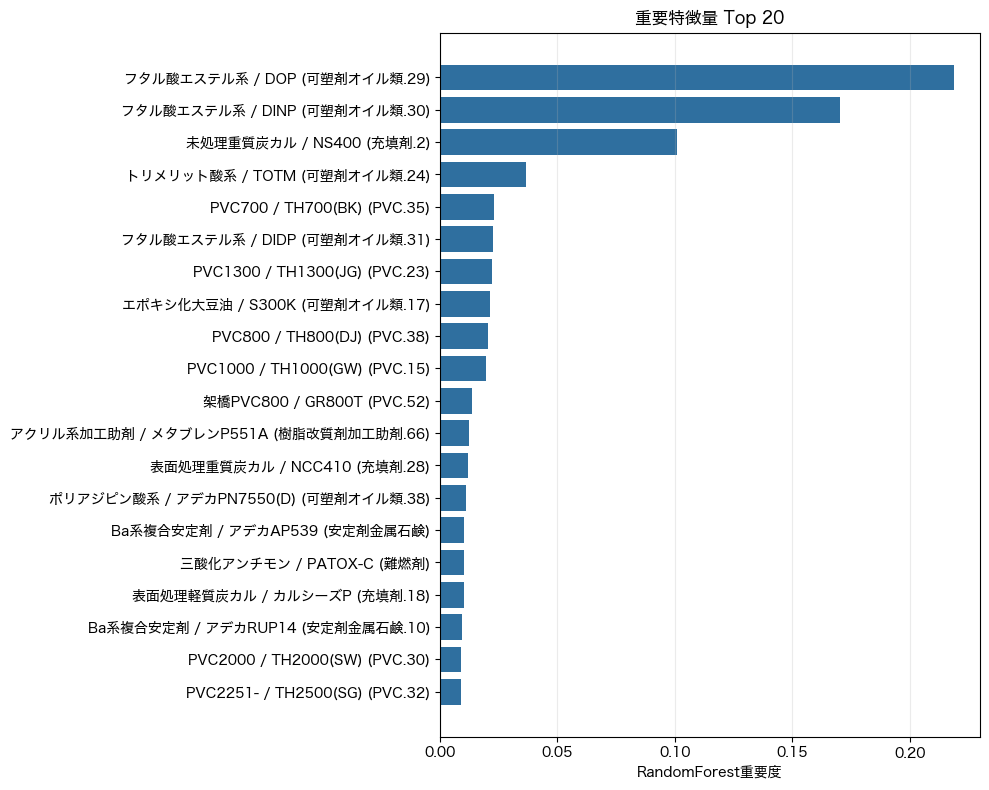

In [4]:
plot_df = review.head(20).sort_values("importance")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_df["display_name"], plot_df["importance"], color="#2f6f9f")
ax.set_title("重要特徴量 Top 20")
ax.set_xlabel("RandomForest重要度")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


## 外れが大きい配合を見る

外れが大きい配合に、上位重要特徴量と主PVC・主可塑剤を付けて表示します。


In [5]:
predictions = diagnostics.predictions.copy()
prepared = diagnostics.prepared
X = prepared.X

primary_pvc = group_labels(prepared, "primary_pvc")
primary_plasticizer = group_labels(prepared, "primary_plasticizer")

top_feature_cols = review["column"].head(12).tolist()
top_feature_names = review.set_index("column")["display_name"].to_dict()

outliers = predictions.head(30).copy()
outliers["primary_pvc"] = primary_pvc.loc[outliers.index].values
outliers["primary_plasticizer"] = primary_plasticizer.loc[outliers.index].values
for column in top_feature_cols:
    outliers[top_feature_names[column]] = X.loc[outliers.index, column].values

display(outliers)


,row_id,actual,predicted,error,abs_error,primary_pvc,primary_plasticizer,フタル酸エステル系 / DOP (可塑剤オイル類.29),フタル酸エステル系 / DINP (可塑剤オイル類.30),未処理重質炭カル / NS400 (充填剤.2),トリメリット酸系 / TOTM (可塑剤オイル類.24),PVC700 / TH700(BK) (PVC.35),フタル酸エステル系 / DIDP (可塑剤オイル類.31),PVC1300 / TH1300(JG) (PVC.23),エポキシ化大豆油 / S300K (可塑剤オイル類.17),PVC800 / TH800(DJ) (PVC.38),PVC1000 / TH1000(GW) (PVC.15),架橋PVC800 / GR800T (PVC.52),アクリル系加工助剤 / メタブレンP551A (樹脂改質剤加工助剤.66)
783,CP0000000000993,2.6,23.849467,21.249467,21.249467,PVC1000 / TH1000(GW) (PVC.15),フタル酸エステル系 / DINP (可塑剤オイル類.30),0.0,40.0,5.0,0.0,0.0,0.0,0.0,3.0,0.0,100.0,0.0,1.5
3004,CP0000000003854,13.9,25.564950,11.664950,11.664950,E・PVC2251- / TE2800 (PVC.13),ポリアジピン酸系 / アデカPN310 (可塑剤オイル類.53),0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0
879,CP0000000001117,9.1,20.172983,11.072983,11.072983,PVC700 / TH700(BK) (PVC.35),ポリアジピン酸系 / ポリサイザW2050 (可塑剤オイル類.41),0.0,15.0,30.0,0.0,100.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0
4489,CP1000000007456,15.4,25.565000,10.165000,10.165000,PVC1300 / TH1300(JG) (PVC.23),フタル酸エステル系 / DINP (可塑剤オイル類.30),0.0,43.0,0.0,0.0,0.0,0.0,100.0,5.0,0.0,0.0,0.0,1.5
2427,CP0000000003019,12.9,22.379222,9.479222,9.479222,PVC1300 / TH1300(JG) (PVC.23),ポリアジピン酸系 / ポリサイザW2350 (可塑剤オイル類.39),0.0,40.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0
1616,CP0000000002101,33.3,23.864917,-9.435083,9.435083,PVC2000 / TH2000(SW) (PVC.30),ポリアジピン酸系 / ポリサイザW2050 (可塑剤オイル類.41),0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.5
2761,CP0000000003370,6.7,15.751333,9.051333,9.051333,PVC1000 / TH1000(GW) (PVC.15),エポキシ化大豆油 / S300K (可塑剤オイル類.17),1.5,0.0,0.0,0.0,0.0,0.0,0.0,1.5,0.0,40.0,0.0,0.0
1445,CP0000000001903,5.8,14.849222,9.049222,9.049222,架橋PVC800 / GR800T (PVC.52),フタル酸エステル系 / DOP (可塑剤オイル類.29),85.0,0.0,25.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,100.0,2.0
4522,CP1000000007609,11.3,20.071000,8.771000,8.771000,PVC-650 / TH500(MG) (PVC.41),フタル酸エステル系 / DINP (可塑剤オイル類.30),0.0,39.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,1.0
1262,CP0000000001618,28.5,19.826122,-8.673878,8.673878,(no PVC),フタル酸エステル系 / DOP (可塑剤オイル類.29),20.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0


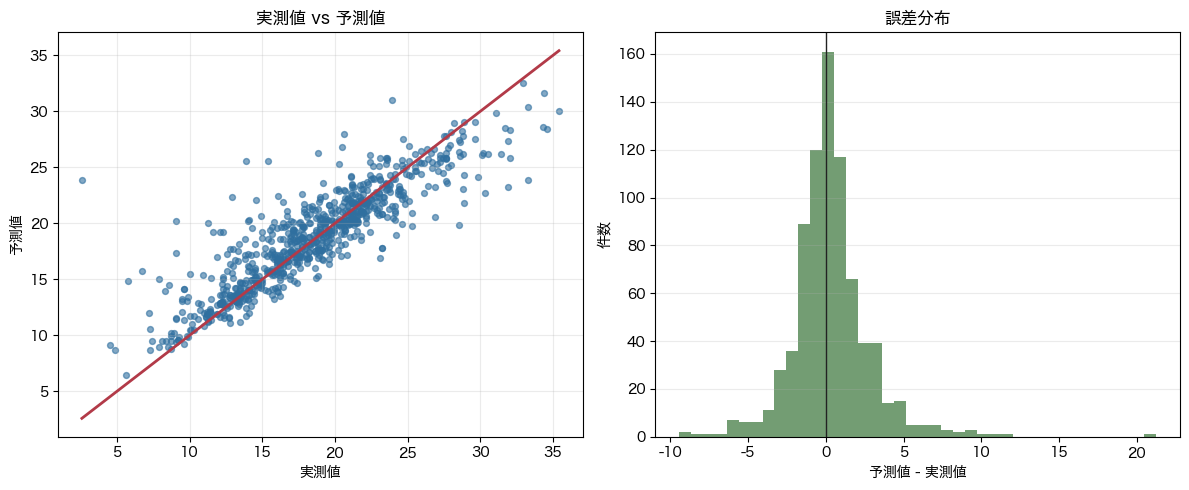

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(predictions["actual"], predictions["predicted"], s=18, alpha=0.6, color="#2f6f9f")
min_value = min(predictions["actual"].min(), predictions["predicted"].min())
max_value = max(predictions["actual"].max(), predictions["predicted"].max())
ax.plot([min_value, max_value], [min_value, max_value], color="#b23a48", linewidth=2)
ax.set_xlabel("実測値")
ax.set_ylabel("予測値")
ax.set_title("実測値 vs 予測値")
ax.grid(alpha=0.25)

ax = axes[1]
ax.hist(predictions["error"], bins=40, color="#5b8c5a", alpha=0.85)
ax.axvline(0, color="#222222", linewidth=1)
ax.set_xlabel("予測値 - 実測値")
ax.set_ylabel("件数")
ax.set_title("誤差分布")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


## 外れ配合を主PVC・主可塑剤で集計する

平均絶対誤差が大きいグループは、モデルが苦手な材料系列の候補です。ただし件数が少ないグループは偶然の影響が大きいため、`count` も一緒に見ます。


In [7]:
error_groups = predictions.copy()
error_groups["primary_pvc"] = primary_pvc.loc[error_groups.index].values
error_groups["primary_plasticizer"] = primary_plasticizer.loc[error_groups.index].values

pvc_error = (
    error_groups.groupby("primary_pvc")
    .agg(count=("abs_error", "size"), mean_abs_error=("abs_error", "mean"), max_abs_error=("abs_error", "max"))
    .query("count >= 10")
    .sort_values("mean_abs_error", ascending=False)
)
plasticizer_error = (
    error_groups.groupby("primary_plasticizer")
    .agg(count=("abs_error", "size"), mean_abs_error=("abs_error", "mean"), max_abs_error=("abs_error", "max"))
    .query("count >= 10")
    .sort_values("mean_abs_error", ascending=False)
)

display(pvc_error.head(15))
display(plasticizer_error.head(15))


,count,mean_abs_error,max_abs_error
primary_pvc,,,
(no PVC),13,3.042883,8.673878
PVC2251- / TH2800(SN) (PVC.33),17,2.271795,4.657222
PVC700 / TH700(BK) (PVC.35),23,2.245252,11.072983
PVC2000 / TH2000(SW) (PVC.30),65,2.005275,9.435083
PVC800 / TH800(DJ) (PVC.38),54,1.637674,7.110533
PVC2251- / TH2500(SG) (PVC.32),49,1.637300,8.653767
PVC1300 / TH1400(KG) (PVC.24),78,1.554545,8.253016
PVC1000 / TH1000(GW) (PVC.15),179,1.523579,21.249467
PVC1300 / TH1300(JG) (PVC.23),262,1.461365,10.165000


,count,mean_abs_error,max_abs_error
primary_plasticizer,,,
ポリアジピン酸系 / ポリサイザW2050 (可塑剤オイル類.41),10,3.820832,11.072983
エポキシ化大豆油 / S300K (可塑剤オイル類.17),13,3.447186,9.051333
ポリアジピン酸系 / ポリサイザW2350 (可塑剤オイル類.39),20,2.454582,9.479222
ポリアジピン酸系 / アデカPN7550(D) (可塑剤オイル類.38),12,2.064661,7.596111
トリメリット酸系 / TOTM (可塑剤オイル類.24),75,1.656776,7.594250
フタル酸エステル系 / DINP (可塑剤オイル類.30),234,1.541106,21.249467
フタル酸エステル系 / DIDP (可塑剤オイル類.31),20,1.501103,6.233000
フタル酸エステル系 / DOP (可塑剤オイル類.29),353,1.459373,9.049222


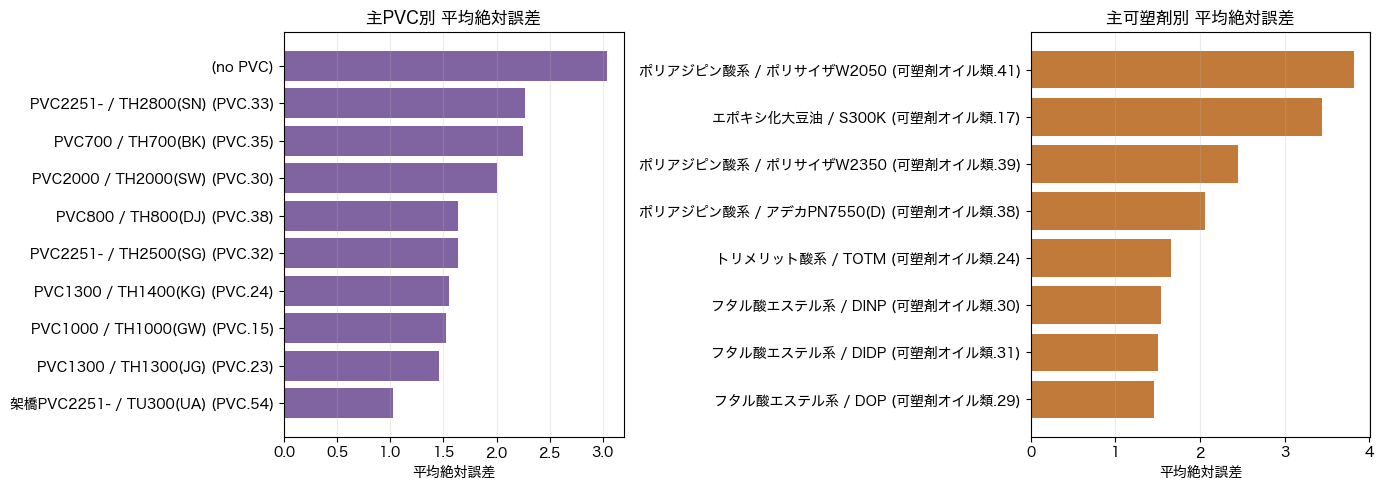

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_pvc = pvc_error.head(12).sort_values("mean_abs_error")
axes[0].barh(plot_pvc.index, plot_pvc["mean_abs_error"], color="#8064a2")
axes[0].set_title("主PVC別 平均絶対誤差")
axes[0].set_xlabel("平均絶対誤差")
axes[0].grid(axis="x", alpha=0.25)

plot_plasticizer = plasticizer_error.head(12).sort_values("mean_abs_error")
axes[1].barh(plot_plasticizer.index, plot_plasticizer["mean_abs_error"], color="#c27a3a")
axes[1].set_title("主可塑剤別 平均絶対誤差")
axes[1].set_xlabel("平均絶対誤差")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()


## 説明変数の欠損と0の扱い

今回のデータでは、説明変数の欠損は基本的にありません。一方で、0が非常に多い疎な配合データです。0を「その原料が入っていない」とみなす前提が妥当か確認します。


In [9]:
zero_summary = feature_missing_zero_summary(target_col=DEFAULT_TARGET)

display(zero_summary[[
    "display_name",
    "missing_count",
    "missing_rate",
    "zero_count",
    "zero_rate",
    "nonzero_count",
    "nonzero_rate",
    "unique_count",
]].head(30))

print("missing columns:", int((zero_summary["missing_count"] > 0).sum()))
print("features with zero_rate >= 0.99:", int((zero_summary["zero_rate"] >= 0.99).sum()))
print("features with zero_rate >= 0.95:", int((zero_summary["zero_rate"] >= 0.95).sum()))


,display_name,missing_count,missing_rate,zero_count,zero_rate,nonzero_count,nonzero_rate,unique_count
6,E・PVC1700 / TE1700(カクガイ) (PVC.11),0,0.0,3929,0.999746,1,0.000254,2
11,PVC1000 / TH1000(シキュウザイ) (PVC.22),0,0.0,3929,0.999746,1,0.000254,2
16,PVC1300 / 3000HY(カクガイ) (PVC.28),0,0.0,3929,0.999746,1,0.000254,2
24,PVC800 / TH800(80) (PVC.39),0,0.0,3929,0.999746,1,0.000254,2
29,塩ビ・酢ビ・コポリマ / UMOH (PVC.46),0,0.0,3929,0.999746,1,0.000254,2
40,その他添加剤 / MC3 (その他添加剤.3),0,0.0,3929,0.999746,1,0.000254,2
42,導電カーボンブラック / A11568BK (その他添加剤.5),0,0.0,3929,0.999746,1,0.000254,2
43,帯電防止剤 / AS95 (その他添加剤.6),0,0.0,3929,0.999746,1,0.000254,2
44,帯電防止剤 / AS960S (その他添加剤.7),0,0.0,3929,0.999746,1,0.000254,2
51,抗菌剤 / バクテキラBM102P(D) (その他添加剤.17),0,0.0,3929,0.999746,1,0.000254,2


missing columns: 0
features with zero_rate >= 0.99: 251
features with zero_rate >= 0.95: 308


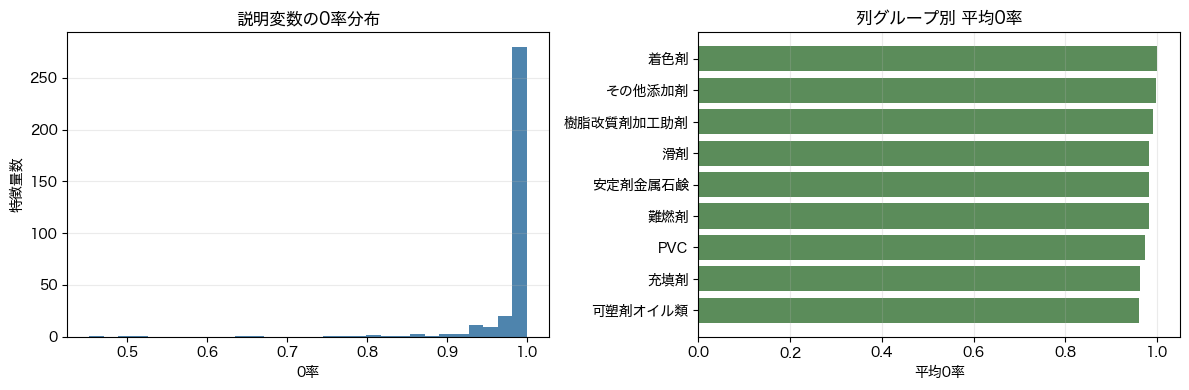

,feature_count,mean_zero_rate,median_zero_rate
base_group,,,
着色剤,1,0.999746,0.999746
その他添加剤,26,0.998150,0.999491
樹脂改質剤加工助剤,33,0.990261,0.998473
滑剤,33,0.983222,0.997964
安定剤金属石鹸,127,0.982198,0.997710
難燃剤,10,0.981069,0.997074
PVC,39,0.972898,0.997201
充填剤,26,0.961852,0.994911
可塑剤オイル類,47,0.961204,0.997455


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(zero_summary["zero_rate"], bins=30, color="#2f6f9f", alpha=0.85)
axes[0].set_xlabel("0率")
axes[0].set_ylabel("特徴量数")
axes[0].set_title("説明変数の0率分布")
axes[0].grid(axis="y", alpha=0.25)

base_group_zero = (
    zero_summary.groupby("base_group")
    .agg(feature_count=("column", "size"), mean_zero_rate=("zero_rate", "mean"), median_zero_rate=("zero_rate", "median"))
    .sort_values("mean_zero_rate", ascending=False)
)
plot_group = base_group_zero.sort_values("mean_zero_rate").tail(15)
axes[1].barh(plot_group.index, plot_group["mean_zero_rate"], color="#5b8c5a")
axes[1].set_xlabel("平均0率")
axes[1].set_title("列グループ別 平均0率")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

display(base_group_zero)


## このNotebookでの確認ポイント

- 重要特徴量上位の原料が、材料知識として妥当か確認する
- 外れ配合上位に共通するPVC・可塑剤・充填剤がないか確認する
- 0が非常に多い列を、特徴量として残すか整理するか検討する
- 0が未使用ではなく未入力を意味する列がないか確認する
